# 01 – Analyse exploratoire (EDA) : AI4I 2020 Predictive Maintenance

Objectif : comprendre les données **avant** d'entraîner le modèle XGBoost.
Ces données serviront aussi de **référence** pour la détection de drift avec Evidently.

## 1. Chargement des données
Le fichier commence par un BOM UTF-8 (caractère invisible) → `encoding="utf-8-sig"` évite que la première colonne s'appelle `\ufeffUDI`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

df = pd.read_csv("../data/ai4i2020.csv", encoding="utf-8-sig")

print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.dtypes

UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

## 2. Qualité des données
Valeurs manquantes, doublons, et unicité des identifiants.

In [14]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum())
print("\nLignes dupliquées :", df.duplicated().sum())
print("UDI unique :", df["UDI"].is_unique)
print("Product ID unique :", df["Product ID"].is_unique)

Valeurs manquantes par colonne :
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Lignes dupliquées : 0
UDI unique : True
Product ID unique : True


## 3. Variable cible : `Machine failure`
On regarde le déséquilibre des classes. Un fort déséquilibre veut dire que l'*accuracy* est trompeuse
(un modèle qui prédit toujours « pas de panne » aurait ~97 % d'accuracy).

Machine failure
0    9661
1     339
Name: count, dtype: int64

Taux de panne : 3.39%


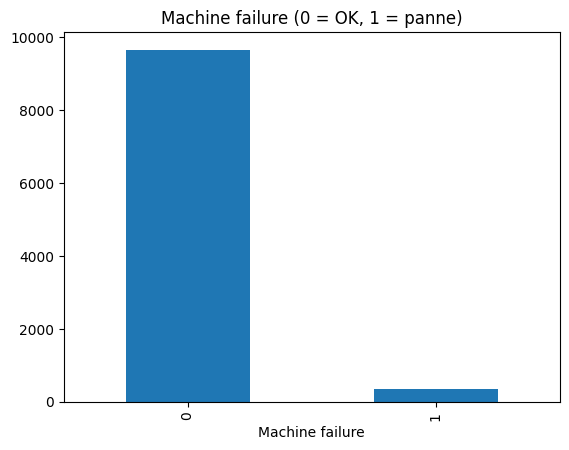

In [20]:
counts = df["Machine failure"].value_counts()
print(counts)
print("\nTaux de panne : {:.2%}".format(df["Machine failure"].mean()))

counts.plot(kind="bar", title="Machine failure (0 = OK, 1 = panne)")
plt.show()

## 4. Types de panne
- **TWF** : usure de l'outil (Tool Wear Failure)
- **HDF** : dissipation de chaleur (Heat Dissipation Failure)
- **PWF** : puissance (Power Failure)
- **OSF** : surcharge (Overstrain Failure)
- **RNF** : panne aléatoire (Random Failure)

On vérifie la cohérence avec `Machine failure`.

In [23]:
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df[failure_types].sum())

any_type = df[failure_types].max(axis=1)
print("\nPanne sans type indiqué :", ((df["Machine failure"] == 1) & (any_type == 0)).sum())
print("Type indiqué sans panne :", ((df["Machine failure"] == 0) & (any_type == 1)).sum())

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

Panne sans type indiqué : 9
Type indiqué sans panne : 18


## 5. Variables numériques (capteurs)

In [25]:
num_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


In [ ]:
df[num_cols].hist(bins=40, figsize=(14, 8))
plt.tight_layout()
plt.show()

## 6. Capteurs vs panne
Quels capteurs séparent les machines saines des machines en panne ?

In [ ]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Machine failure", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
df.groupby("Machine failure")[num_cols].mean().T

## 7. Corrélations

In [ ]:
corr = df[num_cols + ["Machine failure"]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

## 8. Variable `Type` (qualité du produit : L = low, M = medium, H = high)

In [ ]:
type_stats = df.groupby("Type")["Machine failure"].agg(["count", "mean"])
type_stats.columns = ["nb_lignes", "taux_panne"]
type_stats

## 9. Conclusions pour l'entraînement

**Colonnes à exclure des features :**
- `UDI`, `Product ID` : identifiants, aucune information physique.
- `TWF`, `HDF`, `PWF`, `OSF`, `RNF` : ce sont des *détails* de la panne → les utiliser serait une **fuite de données (data leakage)**,
  car en production on ne les connaît pas au moment de la prédiction.

**Features à garder :** `Type` (à encoder) + les 5 capteurs numériques.

**Cible :** `Machine failure`, fortement déséquilibrée →
- split train/test **stratifié**,
- métriques adaptées : precision, recall, F1, PR-AUC (pas l'accuracy seule),
- éventuellement `scale_pos_weight` dans XGBoost.

**Pour le monitoring :** les colonnes features du jeu d'entraînement serviront de **référence Evidently** pour détecter le drift.